# Cuccaro addition, built from individual gates

This notebook demonstrates an unsigned ripple-carry adder implemented directly
with Qiskit `x`, `cx`, and `ccx` calls. **No built-in adder or arithmetic synthesis
routine constructs the circuit.** The default is the optimized circuit from
[Cuccaro et al. (2004), Section 3 / Figure 5](https://arxiv.org/abs/quant-ph/0410184).
We also compare it with the simpler MAJ/UMA chain from Section 2.

We will add basis-state integers, inspect a gate diagram, add coherently on a
superposition, and measure how qubits, gates, and depth grow with input width.
All plotted resources come from constructed circuits, not just fitted formulas.

**Setup:** extract the project ZIP, open a terminal in its root, and run
`python -m pip install -e ".[dev,demo]"`. Launch with
`python -m jupyterlab notebooks/cuccaro_adder_demo.ipynb` and select that Python
environment's kernel. The saved outputs are already visible. A separately
downloaded notebook requires the library from the ZIP to be installed.

In [1]:
import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import qiskit
from IPython.display import Markdown, display
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# Support running from the extracted project root or its notebooks directory.
# An installed package also works when this notebook is elsewhere.
project_root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "cuccaro_adder").is_dir()), None
)
if project_root is not None:
    sys.path.insert(0, str(project_root / "src"))

from cuccaro_adder import (
    adder_resources,
    addition_circuit,
    build_adder,
    count_resources,
    decode_output,
    expected_gate_counts,
    resource_scaling,
)

# Plots use only local resources; no network or quantum account is needed.
output_dir = (project_root or Path.cwd()) / "figures"
output_dir.mkdir(exist_ok=True)
plt.rcParams.update(
    {"font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110}
)
print("Python:", sys.version.split()[0], " | Qiskit:", qiskit.__version__)

Python: 3.12.14  | Qiskit: 2.6.2


## 1. Registers and the arithmetic operation

For two $n$-bit inputs, the circuit has $2n+2$ qubits. The register order is
`a`, `b`, `work`, `cout`, and index 0 is the least significant bit within a register.

| Register | Size | Before | After |
|---|---:|---|---|
| `a` | $n$ | $a$ | $a$, preserved |
| `b` | $n$ | $b$ | $(a+b)\bmod 2^n$ |
| `work` | 1 | 0, required | 0, restored |
| `cout` | 1 | $z$, usually 0 | $z\oplus\lfloor(a+b)/2^n\rfloor$ |

With `cout=0`, combine `cout` and `b` to obtain the full $(n+1)$-bit sum.
`work` is clean scratch space, **not an incoming carry input**. Its initial zero
is a precondition. A superposition or entangled state of the input registers is
allowed; the circuit acts linearly on every basis component.

The qubit basis labels in Qiskit are printed with the largest index at the
left: `cout work b[n-1]...b[0] a[n-1]...a[0]`.

In [2]:
# Automatic width: 5 needs 3 bits, so both input registers have 3 bits.
a, b = 3, 5
prepared = addition_circuit(a, b)
n = max(1, a.bit_length(), b.bit_length())
state = Statevector.from_instruction(prepared)
index = int(np.argmax(state.probabilities()))
answer = decode_output(index, n)
assert np.isclose(state.probabilities()[index], 1)
assert answer.total == a + b and answer.a == a and answer.work == 0
print(f"{a} + {b} = {answer.total}")
print(answer)
print(f"Full register basis label: {index:0{prepared.num_qubits}b}")

3 + 5 = 8
AdditionOutput(a=3, sum_low=0, work=0, carry_out=1, num_bits=3)
Full register basis label: 10000011


The low three sum bits are `000` and `cout=1`, giving $8=1\times2^3+0$.
The first input survives, and the workspace is clean. The arithmetic circuit
itself contains no initialization or measurement; the wrapper prepares the
chosen integers with X gates before composing it.

In [3]:
# Unequal input lengths, explicit padding, zero, one-bit overflow, and long carry examples.
examples = [(0, 0, None), (1, 1, None), (1, 31, None), (7, 7, 3), (3, 5, 5)]
lines = [
    "| a | b | Input bits | Low sum | Carry | Total | Clean workspace |",
    "|---:|---:|---:|---:|---:|---:|:---:|",
]
for a, b, width in examples:
    width = width if width is not None else max(1, a.bit_length(), b.bit_length())
    qc = addition_circuit(a, b, num_bits=width)
    sv = Statevector.from_instruction(qc)
    result = decode_output(int(np.argmax(sv.probabilities())), width)
    assert result.total == a + b and result.a == a and result.work == 0
    lines.append(
        f"| {a} | {b} | {width} | {result.sum_low} | {result.carry_out} | "
        f"{result.total} | {result.work == 0} |"
    )
display(Markdown("\n".join(lines)))

try:
    addition_circuit(8, 1, num_bits=3)
except ValueError as error:
    print("Expected validation error:", error)

| a | b | Input bits | Low sum | Carry | Total | Clean workspace |
|---:|---:|---:|---:|---:|---:|:---:|
| 0 | 0 | 1 | 0 | 0 | 0 | True |
| 1 | 1 | 1 | 0 | 1 | 2 | True |
| 1 | 31 | 5 | 0 | 1 | 32 | True |
| 7 | 7 | 3 | 6 | 1 | 14 | True |
| 3 | 5 | 5 | 8 | 0 | 8 | True |

Expected validation error: num_bits is too small for the supplied inputs


## 2. A two-bit circuit, with every gate exposed

This diagram shows the **bare adder**, excluding basis-state preparation and
measurements. Filled dots are controls, circled plus symbols are targets.
A Toffoli (`ccx`) has two controls. The two-bit case has three Toffolis,
seven CNOTs, no X gates, and logical depth eight.

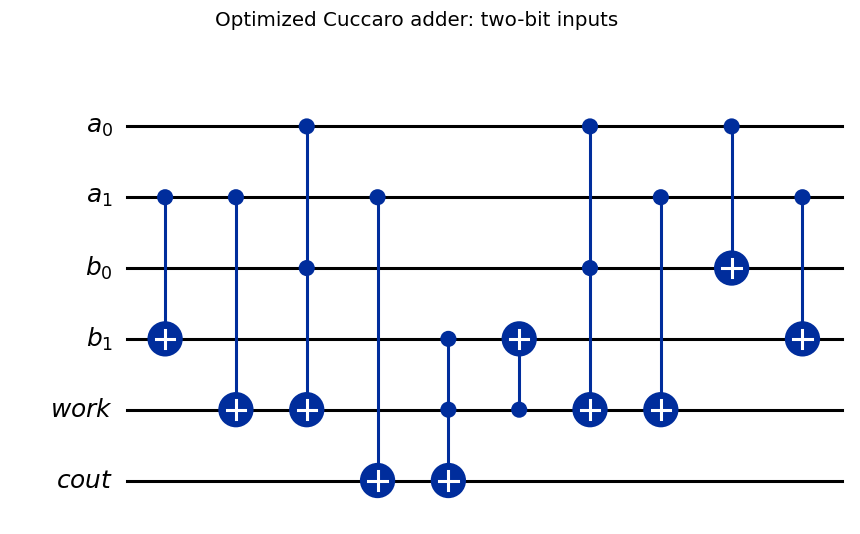

Operations: {'cx': 7, 'ccx': 3}  | Logical depth: 8


In [4]:
small = build_adder(2)
diagram = small.draw(output="mpl", fold=-1, style="iqp", idle_wires=True)
diagram.suptitle("Optimized Cuccaro adder: two-bit inputs", fontsize=13)
diagram.savefig(output_dir / "cuccaro_2bit.png", dpi=200, bbox_inches="tight")
display(diagram)
plt.close(diagram)
print("Operations:", dict(small.count_ops()), " | Logical depth:", small.depth())

## 3. How the ripple works

For classical bits $a_i,b_i,c_i$, the next carry is the majority bit
$c_{i+1}=a_i b_i\oplus a_i c_i\oplus b_i c_i$ and the sum bit is
$s_i=a_i\oplus b_i\oplus c_i$.

The basic construction computes each carry in place with **MAJ**, copies the
highest carry into `cout`, and walks backward with **UMA** (unmajority and add).
The backward sweep restores the input and old carry while writing the sum.
Here are the exact elementary steps used by the library's basic implementation:

```python
# MAJ(a, b, carry)
qc.cx(a, b)
qc.cx(a, carry)
qc.ccx(carry, b, a)  # a now contains the majority / next carry

# UMA(a, b, carry), applied after the higher carry is no longer needed
qc.ccx(carry, b, a)
qc.cx(a, carry)
qc.cx(carry, b)      # b receives the sum; a and carry are restored
```

The optimized default implements the paper's additional changes: use the known
zero initial carry, write the highest carry directly into its output, use the
parallel-friendly UMA arrangement, and reschedule disjoint gates. It uses X
gates as well as CNOTs and Toffolis. The source has comments beside each stage.
Width 1 uses a half adder; widths 2 and 3 have explicit boundary circuits because
the published Figure 5 pseudocode assumes $n\ge4$.

In [5]:
# Both constructions implement the same operation, with different schedules.
for method in ["optimized", "maj_uma"]:
    qc = addition_circuit(5, 6, num_bits=3, method=method)
    result = decode_output(int(np.argmax(Statevector.from_instruction(qc).probabilities())), 3)
    assert result.total == 11 and result.a == 5 and result.work == 0
    bare = adder_resources(3, method=method)
    print(f"{method:10s}: operations={bare.operations}, depth={bare.depth}, result={result.total}")

optimized : operations={'cx': 12, 'ccx': 5, 'x': 2}, depth=10, result=11
maj_uma   : operations={'cx': 13, 'ccx': 6}, depth=17, result=11


## 4. Addition on a superposition

Prepare $a=(|0\rangle+e^{i\pi/3}|1\rangle)/\sqrt2$ and $b=3$, with two-bit
registers. The output has two branches: $0+3=3$ and $1+3=4$. In the second
branch, the low sum wraps to zero and the carry becomes one. The phase must
survive as well as the probabilities. Inspecting the complete complex
statevector checks more than measurement sampling alone.

In [6]:
n = 2
adder = build_adder(n)
coherent = QuantumCircuit(*adder.qregs)
coherent.h(0)
coherent.p(np.pi / 3, 0)  # Relative phase attached to the a=1 branch.
coherent.x(n)
coherent.x(n + 1)  # b = binary 11 = 3.
coherent.compose(adder, inplace=True)
sv = Statevector.from_instruction(coherent)

# Encode the two expected output branches independently of the decoder.
expected = np.zeros(1 << adder.num_qubits, dtype=complex)
expected[0 | (3 << n)] = 1 / np.sqrt(2)
expected[1 | (1 << (2 * n + 1))] = np.exp(1j * np.pi / 3) / np.sqrt(2)
np.testing.assert_allclose(sv.data, expected, atol=1e-12)
for index in np.flatnonzero(np.abs(sv.data) > 1e-10):
    decoded = decode_output(int(index), n)
    print(
        f"a={decoded.a}, sum={decoded.total}, work={decoded.work}, "
        f"amplitude={sv.data[index]:.6f}, probability={abs(sv.data[index]) ** 2:.3f}"
    )
print("Complex amplitudes agree with the coherent arithmetic prediction.")

a=0, sum=3, work=0, amplitude=0.707107+0.000000j, probability=0.500
a=1, sum=4, work=0, amplitude=0.353553+0.612372j, probability=0.500
Complex amplitudes agree with the coherent arithmetic prediction.


## 5. Resource counts: measure the circuit, then check the formulas

`adder_resources(n)` counts the reusable block without input-preparation
overhead. `count_resources(addition_circuit(...))` also counts preparation.
The returned object has per-operation counts, gate count by arity, total gates,
qubits, classical bits, depth, Toffoli count, and T/T-dagger count.

For the optimized construction and $n\ge2$:

| Resource | Exact expression |
|---|---:|
| Logical qubits | $2n+2$ |
| Clean workspace, excluding carry output | 1 |
| Toffoli | $2n-1$ |
| CNOT | $5n-3$ |
| X | $2n-4$ |
| Total logical gates | $9n-8$ |
| Logical depth | $2n+4$ |

At $n=1$ there is one Toffoli and one CNOT, depth two, and an unused workspace
wire retained for a consistent API. `expected_gate_counts` predicts gate counts
from these expressions; it does not inspect the circuit.

In [7]:
rows = resource_scaling(range(1, 65))
for row in rows:
    n = row["num_bits"]
    assert row["operations"] == expected_gate_counts(n)
    assert row["depth"] == (2 if n == 1 else 2 * n + 4)

selected = [r for r in rows if r["num_bits"] in [1, 2, 3, 4, 8, 16, 32, 64]]
table = [
    "| Input bits | Qubits | CCX | CX | X | Gates | Depth |",
    "|---:|---:|---:|---:|---:|---:|---:|",
]
for r in selected:
    op = r["operations"]
    table.append(
        f"| {r['num_bits']} | {r['num_qubits']} | {op.get('ccx', 0)} | "
        f"{op.get('cx', 0)} | {op.get('x', 0)} | {r['gate_count']} | {r['depth']} |"
    )
display(Markdown("\n".join(table)))

bare_count = adder_resources(3)
prepared_count = count_resources(addition_circuit(3, 5, num_bits=3))
print(
    "Preparation adds",
    prepared_count.gate_count - bare_count.gate_count,
    "X gates (the number of 1 bits in 3 and 5).",
)

| Input bits | Qubits | CCX | CX | X | Gates | Depth |
|---:|---:|---:|---:|---:|---:|---:|
| 1 | 4 | 1 | 1 | 0 | 2 | 2 |
| 2 | 6 | 3 | 7 | 0 | 10 | 8 |
| 3 | 8 | 5 | 12 | 2 | 19 | 10 |
| 4 | 10 | 7 | 17 | 4 | 28 | 12 |
| 8 | 18 | 15 | 37 | 12 | 64 | 20 |
| 16 | 34 | 31 | 77 | 28 | 136 | 36 |
| 32 | 66 | 63 | 157 | 60 | 280 | 68 |
| 64 | 130 | 127 | 317 | 124 | 568 | 132 |

Preparation adds 4 X gates (the number of 1 bits in 3 and 5).


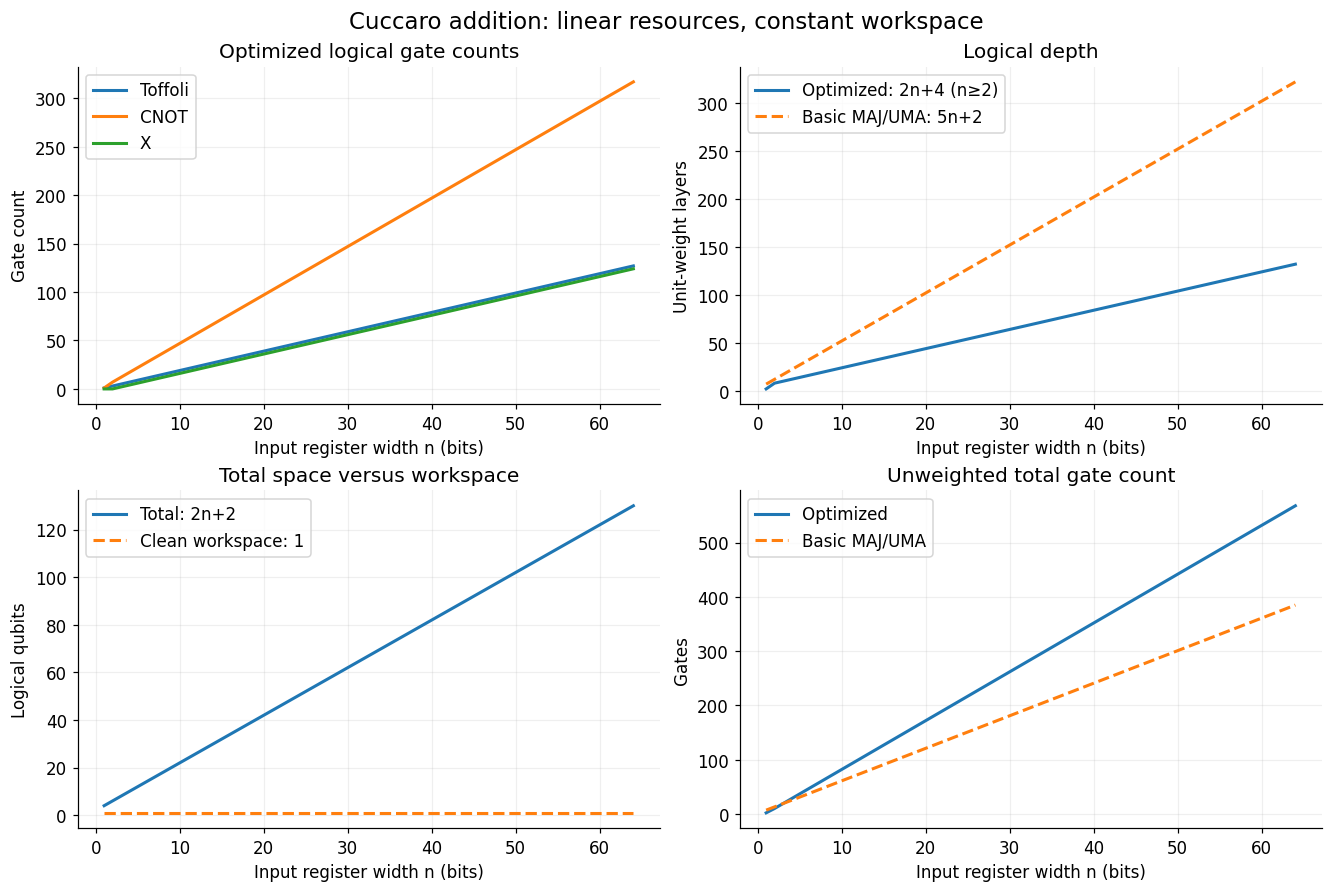

In [8]:
# Compare constructed circuits at each width; no quantum states are simulated here.
basic_rows = resource_scaling(range(1, 65), method="maj_uma")
widths = np.array([r["num_bits"] for r in rows])
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)

ax = axes[0, 0]
for gate, label in [("ccx", "Toffoli"), ("cx", "CNOT"), ("x", "X")]:
    ax.plot(widths, [r["operations"].get(gate, 0) for r in rows], label=label, lw=2)
ax.set(title="Optimized logical gate counts", ylabel="Gate count")
ax.legend()

ax = axes[0, 1]
ax.plot(widths, [r["depth"] for r in rows], label="Optimized: 2n+4 (n≥2)", lw=2)
ax.plot(widths, [r["depth"] for r in basic_rows], "--", label="Basic MAJ/UMA: 5n+2", lw=2)
ax.set(title="Logical depth", ylabel="Unit-weight layers")
ax.legend()

ax = axes[1, 0]
ax.plot(widths, [r["num_qubits"] for r in rows], label="Total: 2n+2", lw=2)
ax.plot(widths, np.ones_like(widths), "--", label="Clean workspace: 1", lw=2)
ax.set(title="Total space versus workspace", ylabel="Logical qubits")
ax.legend()

ax = axes[1, 1]
ax.plot(widths, [r["gate_count"] for r in rows], label="Optimized", lw=2)
ax.plot(widths, [r["gate_count"] for r in basic_rows], "--", label="Basic MAJ/UMA", lw=2)
ax.set(title="Unweighted total gate count", ylabel="Gates")
ax.legend()

for ax in axes.flat:
    ax.set_xlabel("Input register width n (bits)")
    ax.grid(alpha=0.2)
fig.suptitle("Cuccaro addition: linear resources, constant workspace", fontsize=15)
fig.savefig(output_dir / "logical_scaling.png", dpi=200)
fig.savefig(output_dir / "logical_scaling.svg")
plt.show()

**Reading the plots.** Every curve grows linearly, apart from the constant
workspace line and the special one-bit boundary point. Carries temporarily
occupy the `a` register, so there is no length-$n$ scratch-carry register. The
input/output storage still grows as $2n+2$; constant *workspace* does not mean
constant total qubits.

The optimized schedule substantially reduces logical depth and saves one
Toffoli relative to the included basic chain. It does **not** minimize every
resource: its extra CNOT and X gates can make its unweighted gate total larger.
The basic chain has $2n$ Toffolis, $4n+1$ CNOTs, and depth $5n+2$ under Qiskit's
disjoint-gate scheduling. Choosing an implementation requires a cost model.

## 6. Elementary resources: expose the Toffoli cost

In the logical plots above, a three-qubit Toffoli counts as one gate and one
depth layer. That convention is useful for algorithm analysis, but elementary
implementations are more costly. Here we transpile to the exact Clifford+T
basis `x, h, t, tdg, cx`, at optimization level zero, with no coupling map.
The standard decomposition contributes **six CNOTs, seven T/T-dagger gates,
and two Hadamards per Toffoli**. This gives, for optimized $n\ge2$,

$$N_{\mathrm{CX}}=(5n-3)+6(2n-1)=17n-9,$$
$$N_{T+T^\dagger}=7(2n-1)=14n-7.$$

These are costs for the specified decomposition, not fundamental lower bounds.
T-count in the native X/CX/CCX basis is zero only because T gates are still
hidden inside CCX. No hardware routing, error correction, or physical qubits
are modeled here.

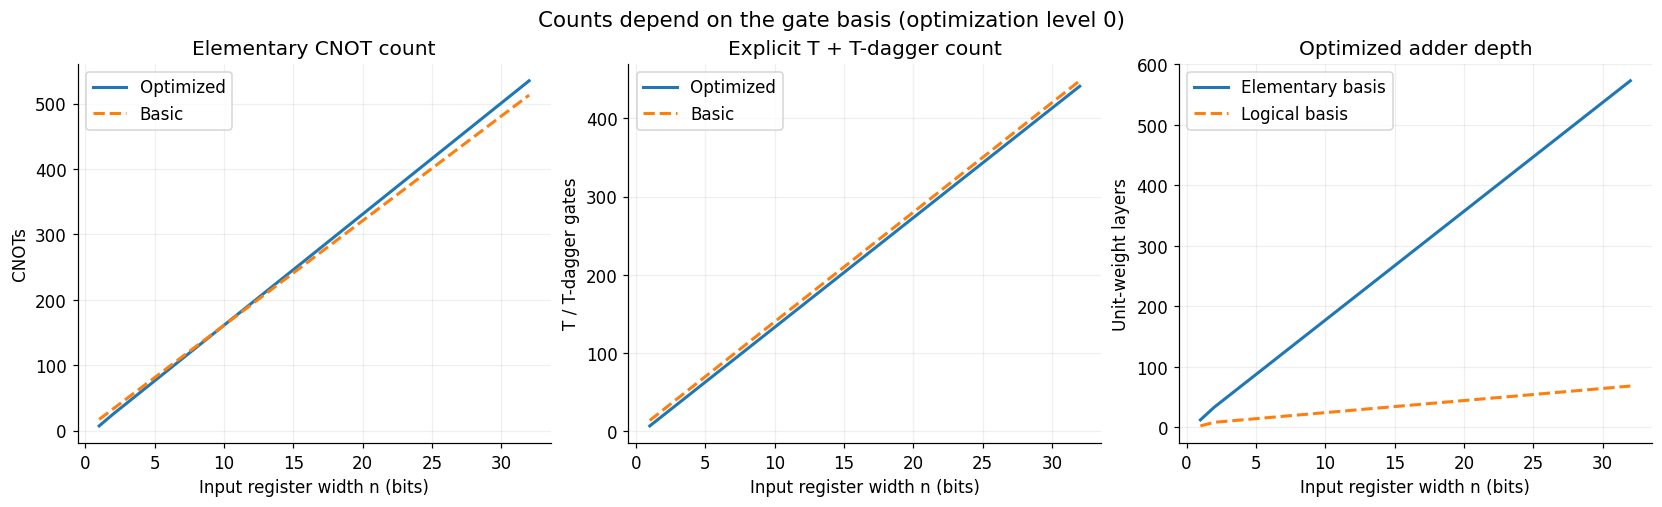

In [9]:
basis = ["x", "h", "t", "tdg", "cx"]
elementary_rows = resource_scaling(range(1, 33), basis_gates=basis)
elementary_basic = resource_scaling(range(1, 33), method="maj_uma", basis_gates=basis)
for row in elementary_rows:
    logical = rows[row["num_bits"] - 1]
    assert row["t_count"] == 7 * logical["toffoli_count"]
    assert row["operations"]["cx"] == logical["operations"]["cx"] + 6 * logical["toffoli_count"]

x = [r["num_bits"] for r in elementary_rows]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
axes[0].plot(x, [r["operations"]["cx"] for r in elementary_rows], label="Optimized", lw=2)
axes[0].plot(x, [r["operations"]["cx"] for r in elementary_basic], "--", label="Basic", lw=2)
axes[0].set(title="Elementary CNOT count", ylabel="CNOTs")
axes[1].plot(x, [r["t_count"] for r in elementary_rows], label="Optimized", lw=2)
axes[1].plot(x, [r["t_count"] for r in elementary_basic], "--", label="Basic", lw=2)
axes[1].set(title="Explicit T + T-dagger count", ylabel="T / T-dagger gates")
axes[2].plot(x, [r["depth"] for r in elementary_rows], label="Elementary basis", lw=2)
axes[2].plot(x, [r["depth"] for r in rows[:32]], "--", label="Logical basis", lw=2)
axes[2].set(title="Optimized adder depth", ylabel="Unit-weight layers")
for ax in axes:
    ax.set_xlabel("Input register width n (bits)")
    ax.grid(alpha=0.2)
    ax.legend()
fig.suptitle("Counts depend on the gate basis (optimization level 0)", fontsize=14)
fig.savefig(output_dir / "elementary_scaling.png", dpi=200)
fig.savefig(output_dir / "elementary_scaling.svg")
plt.show()

The elementary CNOT comparison illustrates the tradeoff: the optimized circuit
has $17n-9$ CNOTs versus $16n+1$ for the basic chain, so it uses more elementary
CNOTs once $n>10$. It still saves seven T/T-dagger gates with this decomposition.
Both circuits remain linear in width. A different optimization level or
hardware connectivity can change counts and depth; compare circuits under
the same basis and compiler settings.

Logical depth is a longest dependency path with equal gate weights, not wall
clock execution time. Elementary depth counts a finer gate basis, so it is
larger even for the same arithmetic operation.

In [10]:
# Export exact plotted logical counts as a small CSV for later reports.
fields = ["num_bits", "num_qubits", "ccx", "cx", "x", "gate_count", "depth"]
with (output_dir / "logical_resources.csv").open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=fields)
    writer.writeheader()
    for row in rows:
        writer.writerow(
            {
                "num_bits": row["num_bits"],
                "num_qubits": row["num_qubits"],
                "ccx": row["operations"].get("ccx", 0),
                "cx": row["operations"].get("cx", 0),
                "x": row["operations"].get("x", 0),
                "gate_count": row["gate_count"],
                "depth": row["depth"],
            }
        )

# A large circuit is easy to construct and count without allocating a statevector.
large = adder_resources(256)
print(
    "256-bit adder:",
    large.num_qubits,
    "qubits,",
    large.gate_count,
    "logical gates,",
    large.depth,
    "logical depth",
)

256-bit adder: 514 qubits, 2296 logical gates, 516 logical depth


## 7. Verification and practical limits

The accompanying commented pytest program checks all input pairs at widths
1--4 using Qiskit statevectors for both implementations and both initial
carry-output values. It also checks random complex superpositions, inverse
operation, workspace cleanup, input preservation, unequal widths, invalid
inputs, and exact resource formulas through 1024 bits.

Large basis-input checks, through 257 bits, use an independent reversible
X/CX/CCX gate interpreter. This verifies long carry propagation without
claiming to simulate an exponentially large quantum state. Small quantum
tests separately check relative phases and coherent carry-output behavior.

Run the suite from the project root with `python -m pytest -q`. The next cell
does the same when running inside the extracted project.

In [11]:
import subprocess

if project_root is not None:
    completed = subprocess.run(
        [sys.executable, "-m", "pytest", "-q"],
        cwd=project_root,
        capture_output=True,
        text=True,
        check=True,
    )
    print(completed.stdout)
else:
    print("Run python -m pytest -q in the extracted project to execute the full suite.")

........................................................................ [ 79%]
...................                                                      [100%]
91 passed in 2.59s



Circuit construction and gate counting need only linear-size circuit data.
Statevector simulation is exponential: this layout has $2n+2$ qubits and thus
$2^{2n+2}$ complex amplitudes. At $n=12$, complex128 amplitudes alone use about
1 GiB, before simulator overhead. Keep simulations small; count large circuits
without simulating them.

This adder is useful as a coherent component inside quantum algorithms. It
does not outperform ordinary classical integer addition on classical inputs.

**References:** [Cuccaro et al.](https://arxiv.org/abs/quant-ph/0410184),
[Qiskit QuantumCircuit](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit),
and [Qiskit Statevector](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Statevector).
Implementation: `src/cuccaro_adder/circuits.py`; resource tools:
`src/cuccaro_adder/resources.py`; tests: `tests/test_cuccaro_adder.py`.